<a href="https://colab.research.google.com/github/shayantiroy20-max/Book-Library-Backend/blob/main/SVP_Assignment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import stft, resample_poly
from math import gcd
from google.colab import files


In [2]:
# Step 1: Upload speech recording
uploaded = files.upload()
filename = next(iter(uploaded))

x, fs = sf.read(filename)

Saving shayanti_roy_clear_indian_female.wav to shayanti_roy_clear_indian_female.wav


In [3]:
# Convert stereo to mono
if x.ndim > 1:
    x = x.mean(axis=1)
# Step 2: Resample to 1000 Hz
target_fs = 1000
if fs != target_fs:
    g = gcd(fs, target_fs)
    x = resample_poly(
        x,
        target_fs // g,
        fs // g
    )
fs = target_fs

In [4]:
# Step 3: Calculate FFT coefficients
X = np.fft.rfft(x)
print("First 10 FFT coefficients:")
print(X[:10])
# Step 4: Calculate STFT coefficients
f, t, Z = stft(
    x,
    fs=fs,
    nperseg=256
)
print("\nSTFT coefficient matrix shape:", Z.shape)
print("First few STFT coefficients:")
print(Z[:5, :5])

First 10 FFT coefficients:
[25.21915685+0.j         -7.8999382 -2.45671574j -4.82100969+3.64239436j
 -3.76365024-3.10822172j 10.26265474+2.2573943j  -1.27631657+0.8914219j
 -5.54446135+1.47241339j -2.58430638-1.29099183j  4.81382737+1.55521893j
 -0.26978891+1.44921458j]

STFT coefficient matrix shape: (129, 109)
First few STFT coefficients:
[[ 4.21103929e-04+0.00000000e+00j  4.72943746e-04+0.00000000e+00j
  -2.21948685e-05+0.00000000e+00j -1.53288651e-04+0.00000000e+00j
  -6.33704090e-04+0.00000000e+00j]
 [-9.83733027e-05+3.48150377e-04j -1.28570773e-04-3.30004151e-04j
  -5.04764357e-05-7.17157921e-05j  6.01051678e-05+1.54962045e-04j
   3.81512041e-04-5.17072851e-04j]
 [-1.85055062e-04-1.02274713e-04j -2.84137374e-04+1.07608784e-04j
   9.71935203e-05-7.45220233e-05j  7.80989756e-05-1.37780630e-04j
   1.90217453e-04+6.39097242e-04j]
 [ 4.59884854e-06-4.60444444e-05j  1.93605409e-04+1.64594108e-04j
  -3.90898923e-05+9.38728652e-05j -5.45447978e-05+3.11955380e-05j
  -6.23570056e-04-2.8246

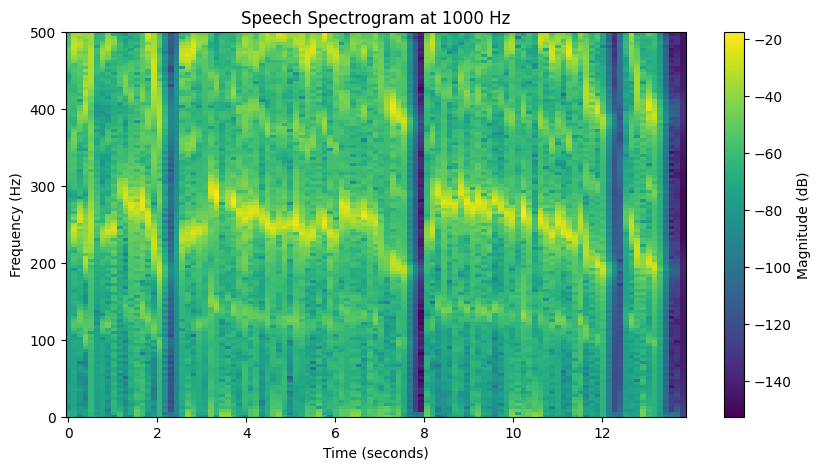

FFT and STFT calculated successfully.


In [5]:
# Step 5: Plot spectrogram
plt.figure(figsize=(10, 5))
plt.pcolormesh(
    t,
    f,
    20 * np.log10(np.abs(Z) + 1e-8),
    shading="auto"
)
plt.title("Speech Spectrogram at 1000 Hz")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(0, 500)
plt.colorbar(label="Magnitude (dB)")
plt.show()
print("FFT and STFT calculated successfully.")